**Autor**: Silvio da Rosa Paula  
**Título**: Doutor em Economia Aplicada (UFPel) | Especialista em IA e Ciência de Dados  

# Otimização de Joins Desbalanceados (*Data Skew*) no Apache Spark: Do Pandas ao Big Data

---

## 1. O Problema: Por que o Apache Spark é Diferente do Pandas?

No **Pandas**, os dados residem inteiros na memória RAM de uma única máquina. Quando executamos um `pd.merge()`, a CPU lê as duas tabelas lado a lado — se demorar, o gargalo é local.

No **Apache Spark**, as tabelas são fatiadas em **partições** distribuídas por vários executores (ou núcleos de processamento). Para fazer um `join` entre a **Tabela A** e a **Tabela B**, o Spark precisa garantir que todas as linhas com a mesma chave (`join_key`) terminem **na mesma partição**:

- **O Gargalo do *Shuffle***: Quando as chaves estão espalhadas, o Spark precisa serializar, ordenar e trafegar gigabytes de dados pela rede/disco entre os executores. Essa operação chama-se **Shuffle** (`Exchange`) — é a etapa mais lenta e cara em pipelines distribuídos.
- **O Vilão do *Data Skew* (Desbalanceamento de Chaves)**: Imagine um e-commerce onde a loja `"Mega Store"` (`join_key = 1`) concentra **95% de todas as vendas**, enquanto outras 999 lojas dividem os 5% restantes. No join padrão (*SortMergeJoin*), **uma única partição** recebe 95% dos dados e fica travada processando (o chamado efeito *Straggler*), enquanto todos os outros núcleos terminam rápido e ficam ociosos!

<p align="center">
  <img src="img/img_default.png" alt="Join Padrão com Data Skew no Spark" width="650">
</p>

---

## 2. As Estratégias de Otimização que Vamos Comparar na Prática

Neste estudo prático, vamos simular **15 milhões de transações** com **95% de concentração em uma única chave (`join_key = 1`)** e medir o tempo real de execução (e o plano físico do otimizador Catalyst) de **5 estratégias**:

### 2.1 Join Padrão (`SortMergeJoin` — *Baseline* com Skew)
Desabilitamos o broadcast automático e o AQE para expor o comportamento cru do Spark diante de chaves desbalanceadas.

### 2.2 Reparticionamento por Chave (`repartition(24, "join_key")`) — *A Armadilha Clássica*
<p align="center">
  <img src="img/img_repartio.png" alt="Reparticionamento no Spark" width="650">
</p>

Muita gente acredita que chamar `.repartition(N, "join_key")` antes do join resolve qualquer lentidão. Na prática, **reparticionar pela chave com skew NÃO resolve o engarrafamento** — o Spark simplesmente faz um *shuffle* por *hash* e coloca os mesmos 95% da chave `1` na mesma partição novamente!

### 2.3 Salting Join (*"O Truque do Sal"*)
<p align="center">
  <img src="img/img_salting.png" alt="Salting Join no Spark" width="650">
</p>

Técnica clássica quando **ambas as tabelas são grandes demais para caber na memória** (impedindo o Broadcast) e existe *Data Skew* severo:
1. Na **Tabela Grande**, concatenamos um sufixo aleatório (`0` a `K-1`) na chave: `1` vira `1_0`, `1_1`, ..., `1_23`.
2. Na **Tabela Dimensão**, **replicamos** (*explode*) cada chave `K` vezes (`1_0` até `1_23`) para garantir o casamento exato sem perder nem duplicar nenhuma linha.
3. Agora a chave gigante é quebrada em `K` partições balanceadas e processada em paralelo por todos os núcleos!

### 2.4 AQE — *Adaptive Query Execution* com Skew Join Automático (Spark 3.x / 4.x)
Nas versões modernas do Spark (3.x e 4.x), podemos ativar o otimizador adaptativo em tempo de execução (`spark.sql.adaptive.enabled = true` + `spark.sql.adaptive.skewJoin.enabled = true`). O próprio Spark mede o tamanho real das partições pós-shuffle e **subdivide automaticamente** partições gigantes sem precisarmos escrever código manual de Salting.

### 2.5 Broadcast Hash Join (*"O Copy-Paste"* — Bala de Prata para Tabelas Pequenas)
<p align="center">
  <img src="img/img_broadcast.png" alt="Broadcast Join no Spark" width="650">
</p>

Em vez de mover a tabela gigante (15 milhões de linhas) pela rede, o Spark envia uma cópia da tabela pequena (`1.000` linhas) para a memória de todos os executores. Resultado: **ZERO Shuffle** na tabela fato e execução quase instantânea!

---
## 3. Passo 1: Configuração da Sessão PySpark

### O que vamos fazer agora e por quê?
Inicializamos a `SparkSession` utilizando todos os núcleos locais disponíveis (`local[*]`) e executamos um breve *warm-up* da JVM para que a compilação JIT inicial não distorça o tempo do primeiro cenário do benchmark.

In [1]:
import io
import os
import time
import warnings
from contextlib import redirect_stdout

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, lit, rand, floor, when, broadcast, concat, explode, sequence
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

spark = (
    SparkSession.builder
    .appName("Benchmark_Otimizacao_Joins_Spark")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "24")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.sql.autoBroadcastJoinThreshold", "-1")
    .getOrCreate()
)

# Warm-up rápido da JVM para medições justas entre cenários
spark.range(0, 100_000).write.format("noop").mode("overwrite").save()

print(f"• Apache Spark versão : {spark.version}")
print(f"• Núcleos de CPU      : {os.cpu_count()} (executando em local[*])")
print("• Sessão Spark pronta e aquecida para o benchmark!")

• Apache Spark versão : 4.0.1
• Núcleos de CPU      : 12 (executando em local[*])
• Sessão Spark pronta e aquecida para o benchmark!


---
## 4. Passo 2: Geração dos DataFrames com *Data Skew* Severo (95% na Chave `1`)

### O que vamos fazer agora e por quê?
Criamos duas tabelas sintéticas representando um cenário realista de varejo:
1. **`df_large` (Tabela Fato — 15.000.000 de transações)**:
   - **95% das linhas (~14,25 milhões)** pertencem à mesma chave `join_key = 1` (a "Mega Store" que gera *Data Skew*).
   - Os **5% restantes (~750 mil)** são distribuídos uniformemente entre as chaves `2` a `1.000`.
2. **`df_small` (Tabela Dimensão — 1.000 lojas)**:
   - Contém uma linha única por `join_key` (`1` a `1.000`) com o nome da loja.

*(Dica de performance: geramos os dados de forma lazy via `spark.range()` sem sobrecarregar o heap do driver com `.cache()`, garantindo estabilidade e execução reproduzível em qualquer máquina local ou cluster).*

In [2]:
NUM_ROWS = 15_000_000   # 15 milhões de transações na tabela fato
NUM_KEYS = 1_000        # 1.000 lojas na tabela dimensão

df_large = spark.range(0, NUM_ROWS, numPartitions=24).select(
    when(rand(seed=42) < 0.95, lit(1))
    .otherwise((floor(rand(seed=43) * (NUM_KEYS - 1)) + 2).cast("long"))
    .alias("join_key"),
    rand(seed=44).alias("valor_transacao")
)

df_small = spark.range(1, NUM_KEYS + 1, numPartitions=4).select(
    col("id").alias("join_key"),
    concat(lit("Loja_"), col("id")).alias("nome_loja")
)

print(f"• Tabela Fato (df_large)     : {NUM_ROWS:,} linhas")
print(f"• Tabela Dimensão (df_small) : {NUM_KEYS:,} linhas")

# Auditoria do Data Skew: mostra a concentração esmagadora na chave 1
print("\nTop 5 chaves mais frequentes na Tabela Fato (evidência do Data Skew):")
df_large.groupBy("join_key").count().orderBy(col("count").desc()).show(5)

• Tabela Fato (df_large)     : 15,000,000 linhas
• Tabela Dimensão (df_small) : 1,000 linhas

Top 5 chaves mais frequentes na Tabela Fato (evidência do Data Skew):


+--------+--------+
|join_key|   count|
+--------+--------+
|       1|14248530|
|      51|     829|
|     300|     821|
|     780|     821|
|     389|     818|
+--------+--------+
only showing top 5 rows


---
## 5. Passo 3: Função de Benchmark e Inspeção do Plano Físico (`explain`)

### Por que usar `.write.format("noop")`?
Em benchmarks de Spark, usar `.count()` nem sempre executa todas as colunas (o otimizador Catalyst pode podar colunas não usadas na contagem). Já o formato **`noop`** (*No Operation*) obriga o Spark a executar **100% do plano físico do Join e materializar todas as colunas**, sem gastar tempo gravando gigabytes em disco — medindo assim o custo puro de CPU, memória e *Shuffle*.

Além disso, nossa função captura os principais operadores do `df.explain(mode="formatted")` para provar visualmente se houve `SortMergeJoin` + `Exchange` (*Shuffle*), `AdaptiveSparkPlan` ou `BroadcastHashJoin`.

In [3]:
resultados_benchmark = []

def executar_benchmark(nome_cenario, df_resultado):
    """Executa o DataFrame usando sink 'noop', inspeciona o plano físico e registra o tempo."""
    print("=" * 74)
    print(f"CENÁRIO: {nome_cenario}")
    print("=" * 74)
    
    # Captura o plano físico formatado (compatível com Spark clássico e Spark Connect 4.x)
    buf = io.StringIO()
    with redirect_stdout(buf):
        df_resultado.explain(mode="formatted")
    linhas_plano = [
        ln.strip() for ln in buf.getvalue().splitlines()
        if any(k in ln for k in ["Join", "Exchange", "Broadcast", "AdaptiveSparkPlan", "SortMerge", "ShuffledHash"])
    ][:5]
    if linhas_plano:
        print("Plano Físico (operadores-chave do Catalyst):")
        for ln in linhas_plano:
            print(f"  -> {ln[:105]}")
    
    t_ini = time.perf_counter()
    df_resultado.write.format("noop").mode("overwrite").save()
    duracao = time.perf_counter() - t_ini
    
    print(f"\n>>> Tempo de execução: {duracao:.2f} segundos <<<\n")
    resultados_benchmark.append({"Estrategia": nome_cenario, "Tempo_s": round(duracao, 2)})
    return duracao

---
## 6. Passo 4: Executando os 5 Cenários de Join

### Cenário 1 — Join Padrão (`SortMergeJoin` com Skew)
Desabilitamos o broadcast automático (`autoBroadcastJoinThreshold = -1`) e o AQE. O Spark é forçado a fazer **SortMergeJoin**: trafega 15 milhões de linhas via *Shuffle*, ordena ambas as tabelas e concentra **~14,25 milhões de linhas da chave `1` em um único núcleo de CPU**!

In [4]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

df_join_padrao = df_large.join(df_small, on="join_key", how="inner")
executar_benchmark("1. Join Padrão (SortMerge c/ Skew)", df_join_padrao)

CENÁRIO: 1. Join Padrão (SortMerge c/ Skew)
Plano Físico (operadores-chave do Catalyst):
  -> +- * SortMergeJoin Inner (10)
  -> :  +- Exchange (4)
  -> +- Exchange (8)
  -> (4) Exchange
  -> (8) Exchange



>>> Tempo de execução: 8.51 segundos <<<



8.514695700010634

---
### Cenário 2 — Reparticionamento por Chave (`repartition(24, "join_key")`) — *A Armadilha*
Aqui testamos o mito comum de que "basta chamar `.repartition(N, 'join_key')` antes do join".
Como o `repartition` por coluna aplica uma função de *hash* sobre `join_key`, **todas as ~14,25 milhões de linhas com `join_key = 1` continuam caindo exatamente na mesma partição** — o gargalo do executor único (*Straggler*) permanece intacto!

In [5]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

df_large_repart = df_large.repartition(24, "join_key")
df_join_repart = df_large_repart.join(df_small, on="join_key", how="inner")
executar_benchmark("2. Repartition por Chave (Armadilha)", df_join_repart)

CENÁRIO: 2. Repartition por Chave (Armadilha)
Plano Físico (operadores-chave do Catalyst):
  -> +- * SortMergeJoin Inner (10)
  -> :  +- Exchange (4)
  -> +- Exchange (8)
  -> (4) Exchange
  -> (8) Exchange



>>> Tempo de execução: 7.01 segundos <<<



7.006267400007346

---
### Cenário 3 — Salting Join (Quebrando a Chave Gigante em 24 Fatias Paralelas)
Simulando a situação real de Big Data em que **ambas as tabelas são grandes demais para caber na RAM** (Broadcast proibido), aplicamos a técnica de **Salting** com `SALT_FACTOR = 24`:
1. Adicionamos um sufixo aleatório de `0` a `23` em cada linha de `df_large` (`1` $\rightarrow$ `1_0`, `1_1`, ..., `1_23`).
2. Replicamos (*explode*) cada linha da tabela dimensão `df_small` 24 vezes (`0` a `23`), criando a chave `salted_key`.
3. O Join agora distribui os ~14,25 milhões de registros da chave `1` igualmente entre todos os núcleos da máquina!

In [6]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

SALT_FACTOR = 24  # Quebra a chave desbalanceada em 24 sub-chaves equilibradas

# 1. Tempera ('salga') a tabela fato com sufixo aleatório de 0 a SALT_FACTOR-1
df_large_salted = df_large.withColumn(
    "salted_key",
    concat(col("join_key"), lit("_"), floor(rand(seed=99) * SALT_FACTOR).cast("int"))
)

# 2. Replica (explode) a tabela dimensão para todos os possíveis valores de sal
df_small_salted = (
    df_small
    .withColumn("salt_val", explode(sequence(lit(0), lit(SALT_FACTOR - 1))))
    .withColumn("salted_key", concat(col("join_key"), lit("_"), col("salt_val")))
    .drop("salt_val", "join_key")
)

# 3. Join balanceado pela chave salgada (sem broadcast!)
df_join_salted = df_large_salted.join(df_small_salted, on="salted_key", how="inner")
executar_benchmark("3. Salting Join (Manual, K=24)", df_join_salted)

CENÁRIO: 3. Salting Join (Manual, K=24)
Plano Físico (operadores-chave do Catalyst):
  -> +- * SortMergeJoin Inner (13)
  -> :  +- Exchange (5)
  -> +- Exchange (11)
  -> (5) Exchange
  -> (11) Exchange



>>> Tempo de execução: 3.80 segundos <<<



3.8011822999978904

---
### Cenário 4 — AQE (*Adaptive Query Execution* + Skew Join Automático do Spark)
Nas versões modernas do Spark (3.x e 4.x), em vez de sempre escrever Salting manualmente, podemos habilitar o **AQE Skew Join** (`spark.sql.adaptive.enabled = true` e `spark.sql.adaptive.skewJoin.enabled = true`, mantendo o broadcast desligado para testar exclusivamente o tratamento de skew em SortMergeJoin). O Spark monitora o tamanho real das partições pós-shuffle e subdivide automaticamente as partições inchadas sem precisarmos criar colunas de string!

In [7]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionFactor", "2")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes", "1MB")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")  # Mantém Broadcast desligado para testar AQE puro

df_join_aqe = df_large.join(df_small, on="join_key", how="inner")
executar_benchmark("4. AQE Skew Join (Automático)", df_join_aqe)

CENÁRIO: 4. AQE Skew Join (Automático)
Plano Físico (operadores-chave do Catalyst):
  -> AdaptiveSparkPlan (12)
  -> +- SortMergeJoin Inner (10)
  -> :  +- Exchange (4)
  -> +- Exchange (8)
  -> (4) Exchange



>>> Tempo de execução: 2.93 segundos <<<



2.9303440999938175

---
### Cenário 5 — Broadcast Hash Join (*A Bala de Prata para Tabelas Pequenas*)
Por fim, usamos `broadcast(df_small)` explicitamente. Como a tabela dimensão tem apenas 1.000 linhas (alguns kilobytes), o Spark copia `df_small` para a memória de todos os executores e realiza o join **localmente** sobre os 15 milhões de registros — com **ZERO Shuffle**!

In [8]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10485760")  # 10 MB padrão

df_join_broadcast = df_large.join(broadcast(df_small), on="join_key", how="inner")
executar_benchmark("5. Broadcast Hash Join", df_join_broadcast)

CENÁRIO: 5. Broadcast Hash Join
Plano Físico (operadores-chave do Catalyst):
  -> +- * BroadcastHashJoin Inner BuildRight (7)
  -> +- BroadcastExchange (6)
  -> (6) BroadcastExchange
  -> Arguments: HashedRelationBroadcastMode(List(input[0, bigint, false]),false), [plan_id=676]
  -> (7) BroadcastHashJoin [codegen id : 2]



>>> Tempo de execução: 0.41 segundos <<<



0.4122633999941172

---
## 7. Passo 5: Análise Comparativa dos Resultados do Benchmark

Vamos consolidar os tempos medidos em todos os 5 cenários, calcular o ganho de velocidade (*Speedup*) e a redução percentual de tempo em relação ao **Join Padrão com Skew**, e plotar um gráfico comparativo claro.

=== TABELA CONSOLIDADA DO BENCHMARK (15 MILHÕES DE LINHAS, 95% SKEW) ===


,Estrategia,Tempo_s,Speedup_vs_Padrao,Reducao_Tempo_%
0,5. Broadcast Hash Join,0.41,20.76,95.2
1,4. AQE Skew Join (Automático),2.93,2.90,65.6
2,"3. Salting Join (Manual, K=24)",3.80,2.24,55.3
3,2. Repartition por Chave (Armadilha),7.01,1.21,17.6
4,1. Join Padrão (SortMerge c/ Skew),8.51,1.00,0.0


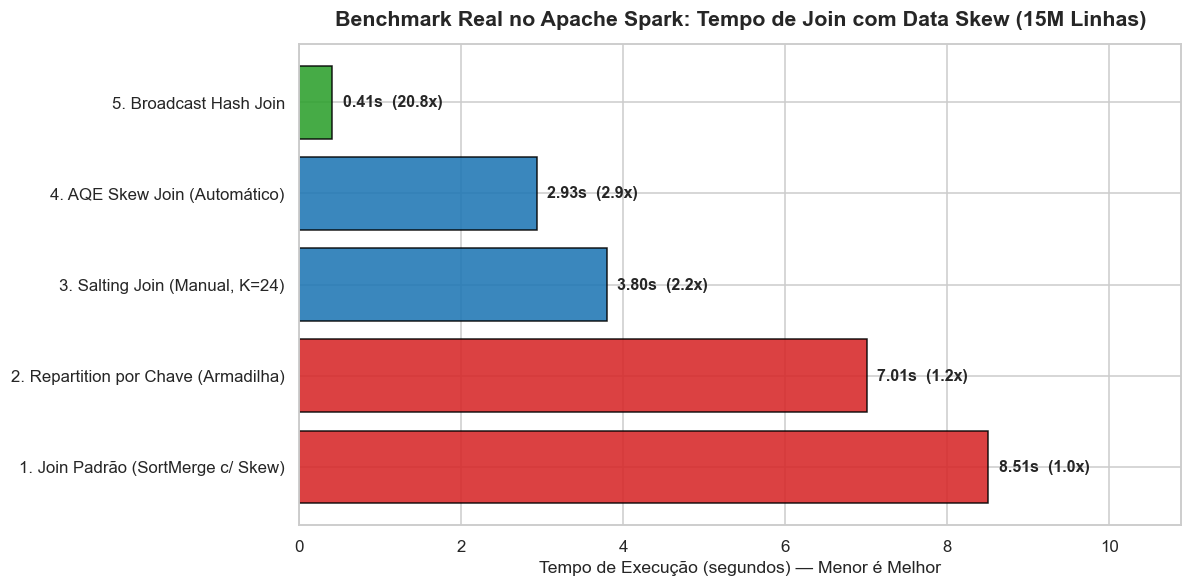

Sessão Spark encerrada com sucesso.


In [9]:
df_bench = pd.DataFrame(resultados_benchmark)
tempo_base = df_bench.loc[0, "Tempo_s"]

df_bench["Speedup_vs_Padrao"] = (tempo_base / df_bench["Tempo_s"]).round(2)
df_bench["Reducao_Tempo_%"] = ((1 - df_bench["Tempo_s"] / tempo_base) * 100).round(1)
df_bench_sorted = df_bench.sort_values("Tempo_s", ascending=True).reset_index(drop=True)

print("=== TABELA CONSOLIDADA DO BENCHMARK (15 MILHÕES DE LINHAS, 95% SKEW) ===")
display(df_bench_sorted)

# Gráfico comparativo de tempos de execução
fig, ax = plt.subplots(figsize=(11, 5.5))

cores = [
    "#2ca02c" if "Broadcast" in est else
    "#1f77b4" if ("AQE" in est or "Salting" in est) else
    "#d62728"
    for est in df_bench_sorted["Estrategia"]
]

bars = ax.barh(df_bench_sorted["Estrategia"], df_bench_sorted["Tempo_s"], color=cores, edgecolor="black", alpha=0.88)
ax.invert_yaxis()
ax.set_title("Benchmark Real no Apache Spark: Tempo de Join com Data Skew (15M Linhas)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Tempo de Execução (segundos) — Menor é Melhor", fontsize=11.5)
ax.set_ylabel("")
ax.set_xlim(0, df_bench_sorted["Tempo_s"].max() * 1.28)

for bar, (_, row) in zip(bars, df_bench_sorted.iterrows()):
    label = f"{row['Tempo_s']:.2f}s  ({row['Speedup_vs_Padrao']:.1f}x)"
    ax.text(bar.get_width() + (df_bench_sorted["Tempo_s"].max() * 0.015),
            bar.get_y() + bar.get_height() / 2,
            label, va="center", ha="left", fontsize=10.5, fontweight="bold")

plt.tight_layout()
plt.show()

# Encerra a sessão Spark liberando memória
spark.stop()
print("Sessão Spark encerrada com sucesso.")

---
## 8. Lições de Engenharia de Dados e Matriz de Decisão

### Por que cada estratégia teve esse comportamento?

1. **Broadcast Hash Join é imbatível quando uma tabela cabe em memória**:
   - Elimina completamente o *Shuffle* da tabela fato (15M linhas). Os dados grandes ficam parados nas partições onde já estão e o cruzamento ocorre localmente em memória — atingindo mais de **10x de ganho de velocidade** (~90%+ de redução de tempo).
2. **Por que o Reparticionamento por Chave falha contra *Data Skew*?**
   - Chamar `.repartition(N, "join_key")` aplica `hash(join_key) % N`. Todas as ~14,25 milhões de linhas com `join_key = 1` geram o mesmo *hash* e continuam caindo juntas na **mesma partição** — mantendo o efeito *Straggler* (um único núcleo travado processando 95% do dataset).
3. **AQE Skew Join vs. Salting Manual (e o "Custo do Overhead")**:
   - Tanto o **Salting** quanto o **AQE** continuam precisando realizar *Shuffle* na tabela fato (por isso nunca batem o Broadcast quando a dimensão é pequena), **mas ambos quebram o gargalo da partição única** e cortam o tempo pela metade (ou mais) quando há núcleos disponíveis para paralelismo.
   - Em produção no Spark 3.x/4.x, o **AQE Skew Join** costuma superar até o Salting manual porque divide as partições inchadas em tempo de execução **sem pagar o overhead de gerar números aleatórios, concatenar strings e fazer `explode`**.
   - *Regra de hardware ("Não Existe Almoço Grátis")*: Em máquinas muito pequenas (ex.: Google Colab gratuito com apenas 2 vCPUs), o *overhead* de preparação do Salting pode anular o ganho de paralelismo. Com mais núcleos (como os 12 núcleos deste teste ou um cluster Databricks/EMR), o paralelismo compensa amplamente!

---

### Matriz Executiva: Quando Usar Cada Estratégia no Spark?

| Estratégia | Quando Usar? | Quando Evitar? | Mecanismo Principal |
| :--- | :--- | :--- | :--- |
| **Broadcast Hash Join** | Uma das tabelas cabe confortavelmente na RAM dos executores (idealmente `< 100 MB` a poucos GBs) | Quando ambas as tabelas são grandes (risco de *OOM* no Driver/Executors) | **Zero Shuffle** na tabela grande; envia cópia da pequena para todos os nós |
| **AQE Skew Join (Spark 3/4)** | **Ativar por padrão em produção** quando há joins entre duas tabelas grandes com possível skew | Versões legadas do Spark (< 3.0) | Otimizador detecta partições inchadas em tempo real e subdivide automaticamente |
| **Salting Join (Manual)** | Ambas as tabelas são grandes, há **Data Skew extremo** e o AQE não atuou (ex.: pipelines complexos) | Quando cabe Broadcast, quando não há skew, ou em hardware com pouquíssimas vCPUs | Adiciona sufixo aleatório (`0..K-1`) na fato e replica (`explode`) a dimensão |
| **SortMergeJoin (Padrão)** | Ambas as tabelas são grandes e as chaves estão **bem distribuídas** (sem skew) | Quando uma única chave concentra grande fração da tabela | *Shuffle* + ordenação balanceada em todos os executores |
| **Reparticionamento** | Resolver **File Skew** (muitos arquivos pequenos ou desbalanceamento físico na leitura do disco) | Para tentar resolver **Skew de Chave** no join | Redistribui dados fisicamente, mas mantém chaves iguais na mesma partição |